# 1. Project objective

## Customer Churn Analysis

### Objective
Analyse customer characteristics associated with churn and develop
classification models to identify customers at higher risk of churn.

### Tools
Python, pandas, matplotlib, seaborn, scikit-learn

# 2. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as stat # statistics Library

# 3. Load data

In [2]:
data = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# check data
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 4. Data inspection

In [3]:
print(data.columns.tolist())
print(data.dtypes)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [4]:
# shape of dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
data.shape

(7043, 21)

In [6]:
# statistic summary
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# check missing values
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
# check duplicates
data.duplicated().sum()

0

In [9]:
## find patterns that explain customer churn
# check Churn - distribution 
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# 5. Data cleaning

In [10]:
# Convert TotalCharges object into numerical and find null
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
data['TotalCharges'].isna().sum()

11

In [11]:
# Drop null data
data = data.dropna(subset=['TotalCharges']).copy()
data['TotalCharges'].isna().sum()

0

In [12]:
data.loc[:,'Churn_binary'] = data.loc[:,'Churn'].map({'Yes': 1, 'No': 0})

In [13]:
data.loc[:,'tenure_group'] = pd.cut(data['tenure'],
                              bins=[0,12,24,48,float('inf')],
                              labels=['0-12 months', '13-24 months', '25-48 months', '49+ months'],
                              include_lowest=True)
# data.head()
data.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12 months
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,0-12 months
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No,0,13-24 months
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,Month-to-month,No,Mailed check,29.75,301.90,No,0,0-12 months
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,25-48 months
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No,0,49+ months


# 6. Exploratory Data Analysis
The effect of contract type, Payment method, Internet service, tenure,  MonthlyCharges, and TotalCharges on churn.

In [14]:
## Q1. What proportion of customers churn?
data["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

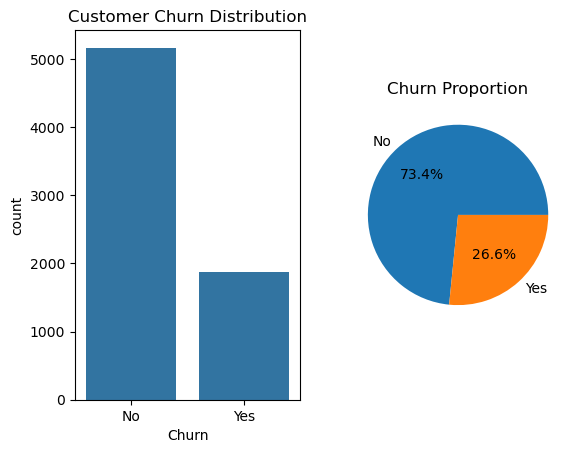

In [15]:
# plot distribution - check if it is balance? how many customers were leaving?
plt.subplot(1,2,1)
sns.figsize=(3,3)
sns.countplot(x='Churn', data=data)
plt.title('Customer Churn Distribution')
#plt.show()

plt.subplot(1,2,2)
data['Churn'].value_counts().plot.pie(autopct='%1.1f%%') # , figsize=(8,8)
plt.title('Churn Proportion')
plt.ylabel('')
plt.show()

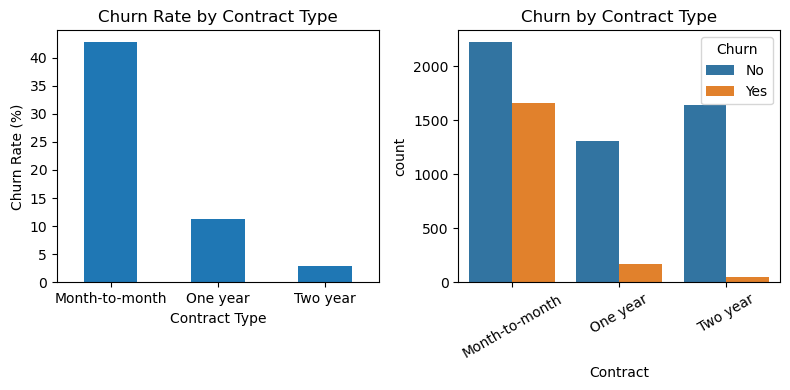

In [16]:
## Q2. Does churn rate differ by contract type?
#contract_churn = (data.groupby('Contract')['Churn']
#                  .value_counts(normalize=True)
#                  .unstack()
#                  .mul(100)
#                  .round(2))
#print(contract_churn)

contract_summary = (data.groupby('Contract').agg(
    customers = ('Churn', 'size'),
    churn_rate = ('Churn', lambda x: (x == 'Yes').mean()*100),
    avg_tenure = ('tenure', 'mean'),
    avg_monthly_charge = ('MonthlyCharges', 'mean'),
    avg_total_charge = ('TotalCharges', 'mean'))
    .round(2)
)


# figure
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
contract_summary['churn_rate'].plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
#plt.show()

plt.subplot(1,2,2)
sns.countplot(x='Contract', hue='Churn', data = data)
plt.xticks(rotation=30)
plt.title('Churn by Contract Type')

plt.tight_layout()
plt.show()


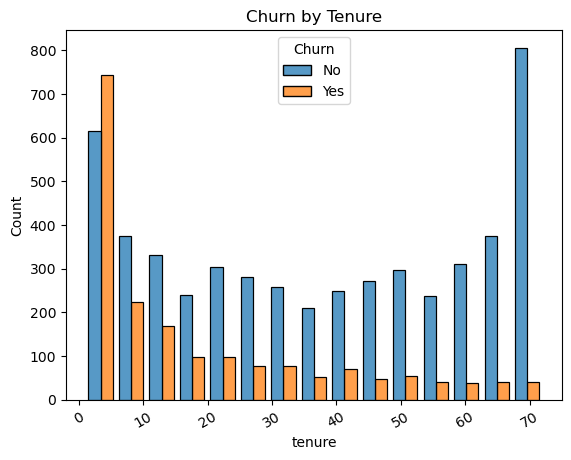

In [17]:
## Q3. Does churn rate differ by tenure?
# Do short-term customers churn more? Do expensive plans increase
tenure_churn = (data.groupby('tenure')['Churn']
    .apply(lambda x:(x=='Yes').mean()*100)
    .round(2))

# figure
sns.histplot(data=data, x='tenure', hue='Churn', multiple='dodge', shrink=.8) #, multiple='stack', bins=30)
plt.xticks(rotation=30)
plt.title('Churn by Tenure')
plt.show()

In [18]:
# tenure_summary
(data.groupby('tenure_group', observed = True).agg(
    customers = ('Churn', 'size'),
    churned_customers = ('Churn', lambda x:(x=='Yes').sum()),
    churn_rates = ('Churn', lambda x: (x=='Yes').sum()/x.size *100),
    # churn_rate=('Churn', lambda x: (x=='Yes').mean()*100),
    avg_monthly_charge = ('MonthlyCharges', 'mean')
    )
    .round(2))

#rates = (data.groupby('tenure_group', observed=True)['Churn']
#    .value_counts(normalize=True)
#    .unstack()
#)
#churn_rate = rates['Yes']*100
#churn_rate.round(1)


,customers,churned_customers,churn_rates,avg_monthly_charge
tenure_group,,,,
0-12 months,2175,1037,47.68,56.17
13-24 months,1024,294,28.71,61.36
25-48 months,1594,325,20.39,65.93
49+ months,2239,213,9.51,73.95


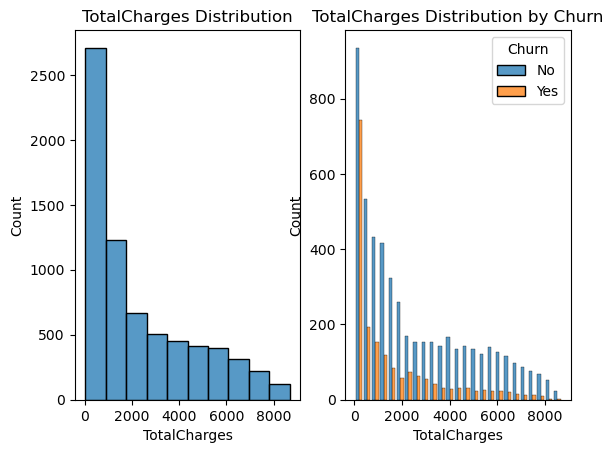

In [19]:
## Q4. Are charges associated with churn?
### Put your MonthlyCharges / TotalCharges distributions and churn comparisons here.
# show distribution of TotalCharges
plt.subplot(1,2,1)
sns.histplot(data = data, x= 'TotalCharges', bins = 10) #bins=range(0, 100, 10))
plt.title('TotalCharges Distribution')
plt.subplot(1,2,2)
sns.histplot(data = data, x='TotalCharges', hue='Churn', multiple='dodge', shrink=.8)
plt.title('TotalCharges Distribution by Churn')
plt.show()


In [20]:
# Filtering  - MonthlyCharge Yes
#high_value = data[(data['MonthlyCharges'] > 70) & (data['Churn'] == 'Yes')]
#print(high_value)

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.27  16.73
Credit card (automatic)    84.75  15.25
Electronic check           54.71  45.29
Mailed check               80.80  19.20


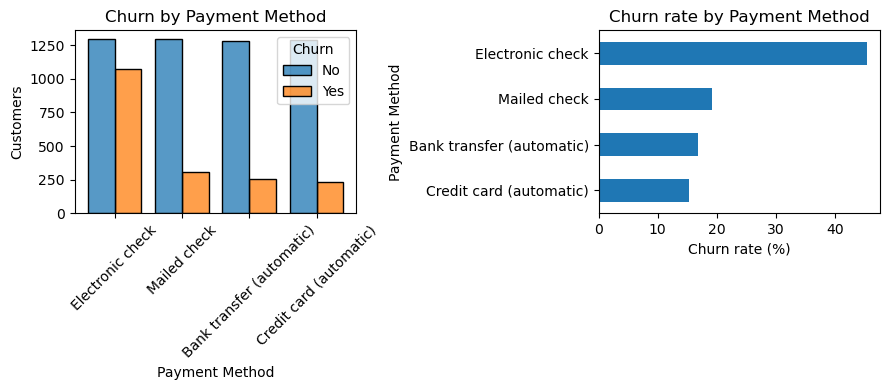

In [21]:
## Q5. What other characteristics are associated with churn?
### Payment method
payment_method_churn = (data.groupby('PaymentMethod')['Churn']
                  .value_counts(normalize=True)
                  .unstack()
                  .mul(100)
                  .round(2))
print(payment_method_churn)

plt.figure(figsize=(9,4))
plt.subplot(1,2,1)
sns.histplot(data = data, x='PaymentMethod', hue='Churn', multiple='dodge', shrink=.8)
plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.xticks(rotation=45)
plt.ylabel('Customers')
# plt.show()

plt.subplot(1,2,2)
payment_method_churn['Yes'].sort_values().plot(kind='barh')
plt.title('Churn rate by Payment Method')
plt.ylabel('Payment Method')
plt.xlabel('Churn rate (%)')

#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Churn               No    Yes
InternetService              
DSL              81.00  19.00
Fiber optic      58.11  41.89
No               92.57   7.43


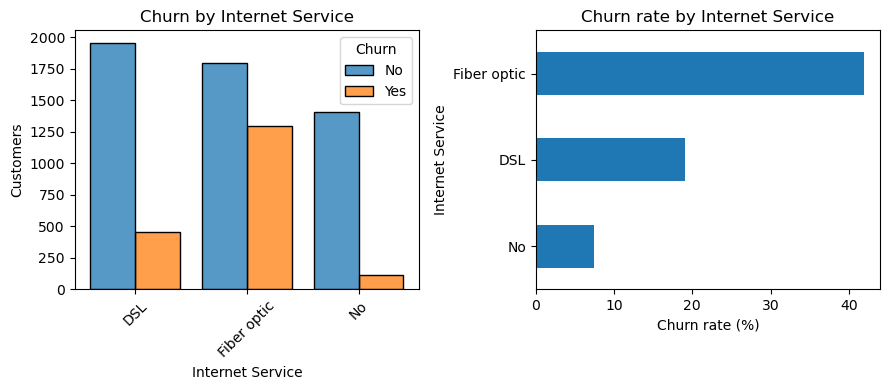

In [22]:
## Q5. What other characteristics are associated with churn?
### internet service
internet_service_churn = (data.groupby('InternetService')['Churn']
                  .value_counts(normalize=True)
                  .unstack()
                  .mul(100)
                  .round(2))
print(internet_service_churn)

plt.figure(figsize=(9,4))
plt.subplot(1,2,1)
sns.histplot(data = data, x='InternetService', hue='Churn', multiple='dodge', shrink=.8)
plt.title('Churn by Internet Service')
plt.xlabel('Internet Service')
plt.xticks(rotation=45)
plt.ylabel('Customers')
# plt.show()

plt.subplot(1,2,2)
internet_service_churn['Yes'].sort_values().plot(kind='barh')
plt.title('Churn rate by Internet Service')
plt.ylabel('Internet Service')
plt.xlabel('Churn rate (%)')

#plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


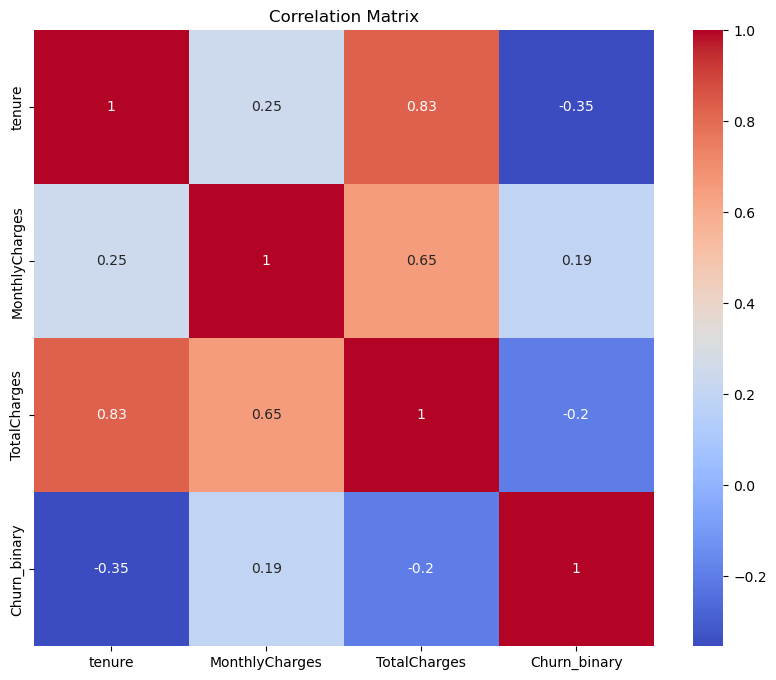

In [23]:
## Q6. Correlation analysis - heatmap
corr = data[['tenure', 'MonthlyCharges','TotalCharges','Churn_binary']].corr(method='pearson')

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [24]:
# Aggregation
data.groupby('Contract').agg(
    customers = ('Churn', 'size'),
    churn_rate = ('Churn', lambda x:(x=='Yes').mean()),
    avg_tenure = ('tenure', 'mean'),
    avg_monthly_charge = ('MonthlyCharges', 'mean'),
    avg_total_charge = ('TotalCharges', 'mean')
)

#a['churn_rate'].plot(kind='bar')
#plt.title('Churn Rate by Contract Type')
#plt.xlabel('Contract Type')
#plt.ylabel('Churn Rate (%)')
#plt.xticks(rotation=0)
#plt.tight_layout()
#plt.show()


,customers,churn_rate,avg_tenure,avg_monthly_charge,avg_total_charge
Contract,,,,,
Month-to-month,3875,0.427097,18.036645,66.398490,1369.254581
One year,1472,0.112772,42.073370,65.079416,3034.683084
Two year,1685,0.028487,57.071810,60.872374,3728.933947


## Key Findings

- Month-to-month customers had substantially higher churn than customers on longer contracts.
- Churn was concentrated among customers with shorter tenure.
- Churn differed across payment methods: electronic check showed higher churn rate than other methods.
- Internet-service type was associated with different churn rates: Churn rate was higher for Fiber optic than DSL.
- Monthly and total charges showed different patterns between churned and retained customers.

## Business Implications

Retention activity could prioritise short-tenure customers on month-to-month contracts and other customer segments showing elevated churn rates.

In [25]:
data.to_csv('../data/cleaned_churn_data.csv', index=False)